# Haslett and Parnell

This notebook presents the `StratAge` implementation of the age modeling approach developed by Haslett and Parnell (2008).

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
from scipy import stats
import arviz as az
import pymc as pm

import stratage
from stratage.geochron import Geochron
import pystrat

import matplotlib.pyplot as plt

In [2]:
np.random.seed(seed=500)

## Synthetic Stratigraphy

Here we're using the same synthetic stratigraphy and geochronology from the [toy example](toy-example.ipynb).

Now, however, we are also representing the stratigraphic heights of the geochronologic samples as random variables.

In [5]:
units = np.array([[0, 1.5],
                  [1.5, 2.2],
                  [2.2, 2.7],
                  [2.7, 3.4],
                  [3.4, 4]])
times = np.array([[0, 1.5],
                  [2.3, 2.5],
                  [3, 3.2],
                  [3.6, 3.9],
                  [4, 4.2]]) - 4.2

n_units = units.shape[0]
n_contacts = n_units - 1

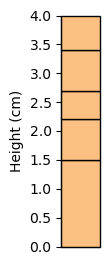

In [4]:
thicknesses = np.diff(units, axis=1).squeeze()
facies = np.array(['sand'] * len(thicknesses))

style = pystrat.Style(np.array(['sand']), 
                      np.array([[252, 193, 130]])/255, 
                      np.array([1]))
section = pystrat.Section(thicknesses, facies)
section.shift_heights(np.min(units[0]))   # make same y axis as heights

fig = plt.figure(figsize=(0.5, 3))
heights_ylim = [np.min(units[:, 0]), np.max(units[:, 1])]
ax = plt.axes(ylim=heights_ylim)
section.plot(style, ax=ax)
ax.set_ylabel('Height (cm)')
ax.set_xticks([])

plt.show()

In [7]:
# temporal uncertainty
sig_t = 0.15

# height uncertainty
sig_h = 0.1

# number of constraints to include
n_constraints = 3

In [8]:
constraint_rvts = []    # random variables for geochronology ages
constraint_heights = [] # deterministic heights for geochronology
constraint_rvhs = []    # random variables for geochronology heights

# bottom (within first unit)
constraint_rvts.append(stats.norm(loc=stats.norm.rvs(loc=times[0, 0], scale=sig_t), scale=sig_t))
constraint_heights.append(0.1)
constraint_rvhs.append(stats.norm(loc=constraint_heights[0], scale=sig_h))
    
# top (within top unit)
constraint_rvts.append(stats.norm(loc=stats.norm.rvs(loc=times[-1, 1], scale=sig_t), scale=sig_t))
constraint_heights.append(3.9)
constraint_rvhs.append(stats.norm(loc=constraint_heights[1], scale=sig_h))

# 3rd constraint in middle
constraint_rvts.append(stats.norm(loc=stats.norm.rvs(loc=times[2, 1], scale=sig_t), scale=sig_t))
constraint_heights.append(2.5)
constraint_rvhs.append(stats.norm(loc=constraint_heights[2], scale=sig_h))

Now visualize the true age model alongside the constraints and the experimental stratigraphy.

In [9]:
t_plot = np.linspace(np.min(times) - 3*sig_t, np.max(times) + 3*sig_t, 400)
h_plot = np.linspace(np.min(constraint_heights) - 3*sig_h, np.max(constraint_heights) + 3*sig_h, 400)

# true age model
t_true, z = stratage.age_depth(units, times)
# parameters for plotting pdfs
tol = 3
scale = 0.75

C:\Users\Adrian\AppData\Local\Temp\ipykernel_25448\473528785.py:36: RuntimeWarning: divide by zero encountered in log10
  idx_pdf = np.log10(cur_pdf) > (np.max(np.log10(cur_pdf)) - tol)


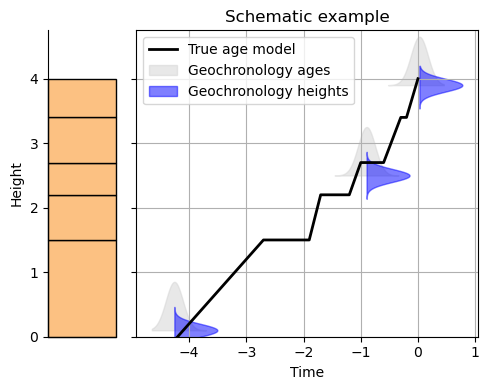

In [20]:
fig, ax = plt.subplots(1, 2, width_ratios=[1, 5], figsize=(5,4), sharey=True)

h = []
lab = []

ax[0].set_ylim([heights_ylim[0]-0.5, heights_ylim[1]+scale])
section.plot(style, ax=ax[0])
ax[0].set_xticks([])
ax[0].set_ylim([0, np.max(z)+scale])
ax[0].set_ylabel('Height')

cur_h = ax[1].plot(t_true, z, label='True age model', color='k', linewidth=2)[0]
h.append(cur_h)
lab.append('True age model')

for ii in range(n_constraints):
    # plot age pdfs
    cur_pdf = constraint_rvts[ii].pdf(t_plot)
    # only plot the part of the pdf that matters
    idx_pdf = np.log10(cur_pdf) > (np.max(np.log10(cur_pdf)) - tol)
    
    # scale it to be visible
    pdf_scale = scale/(np.max(cur_pdf[idx_pdf]) - np.min(cur_pdf[idx_pdf]))
    cur_pdf = constraint_heights[ii] + pdf_scale * cur_pdf
    
    cur_ht = ax[1].fill_between(t_plot[idx_pdf], 
                               cur_pdf[idx_pdf],
                               constraint_heights[ii],
                               linewidth=1,
                               alpha=0.5,
                               color='lightgrey')
    
    # plot height pdfs
    cur_pdf = constraint_rvhs[ii].pdf(h_plot)
    # only plot the part of the pdf that matters
    idx_pdf = np.log10(cur_pdf) > (np.max(np.log10(cur_pdf)) - tol)
    
    # scale it to be visible
    pdf_scale = scale/(np.max(cur_pdf[idx_pdf]) - np.min(cur_pdf[idx_pdf]))
    cur_pdf = constraint_rvts[ii].mean() + pdf_scale * cur_pdf
    
    cur_hh = ax[1].fill_betweenx(h_plot[idx_pdf], 
                               cur_pdf[idx_pdf],
                               constraint_rvts[ii].mean(),
                               linewidth=1,
                               alpha=0.5,
                               color='blue')
h.append(cur_ht)
lab.append('Geochronology ages')
h.append(cur_hh)
lab.append('Geochronology heights')

ax[1].grid()
ax[1].set_xlabel('Time')
ax[1].legend(h, lab)
ax[1].set_title('Schematic example')

plt.tight_layout()

plt.show()

## Geochronology

As `stratage.bchron` also utilizes `stratage.Geochron`. Unlike in `stratage.AgeModel`, however, we can now include the uncertainty on the constraint heights shown above.

In [21]:
geochron = Geochron(constraint_heights, constraint_rvts, rvh=constraint_rvhs, nt=500, ndt=100, prob_threshold=1e-3, neighbors='all')

Constructing increment pdfs.:   0%|          | 0/3 [00:00<?, ?it/s]

Constructing increment pdfs.:   0%|          | 0/3 [00:00<?, ?it/s]

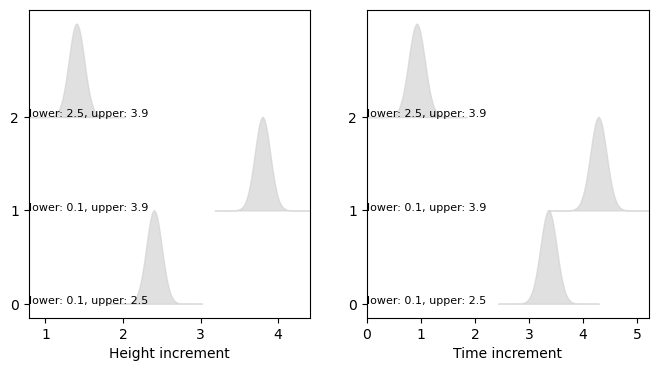

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(8,4))
_ = geochron.plot_increment_pdfs(ax=ax[0], which='height')
_ = geochron.plot_increment_pdfs(ax=ax[1], which='time')

plt.show()

## Least Squares Age-Depth Modeling

The `geochron.model_weights()` function generates the weights for units and contacts for each pair of constraints. These weights identify which contacts and units occur within a given pair of constraints. 

For contacts, the weights $\beta$ are either 0 or 1, because contacts cannot be partially bound by constraints.

For units, the weights $\alpha$ range from 0 to the thickness of the unit. A value equal to the thickness of the unit means that the given unit is completely bounded by a pair of constraints, i.e., no geochronologic constraint occurs within that unit. A value between 0 and the thickness of the unit means that for the given pair of constraints, one occurs within the unit, and the value of the weight quantifies the proportion of the unit that is bound between the constraints. This approach assumes a constant sedimentation rate for the portion of the unit that is partially bound by a constraint.

In [27]:
alpha, beta = geochron.model_weights(units_trim)

print(f'alpha:\n{alpha.T}\nbeta:\n{beta.T}')

alpha:
[[1.4 0.7 0.3 0.  0. ]
 [1.4 0.7 0.5 0.7 0.5]
 [0.  0.  0.2 0.7 0.5]]
beta:
[[1. 1. 0. 0.]
 [1. 1. 1. 1.]
 [0. 0. 1. 1.]]


The values of $\alpha$ and $\beta$ form arrays that define a linear system with respect to time increments:

\begin{align}
\Delta \mathbf{T} &= \alpha\,\mathbf{v}^{-1} + \beta\,\mathbf{t} \\
         &= \begin{bmatrix}\alpha & \beta\end{bmatrix}\,\begin{bmatrix} \mathbf{v}^{-1} \\ \mathbf{t} \end{bmatrix} \\
         &= \mathbf{A}\,\mathbf{m}
\end{align}

where $\Delta \mathbf{T}$ are the mean time increment values, $\mathbf{v}^{-1}$ is $1/v_{i}$ where $v_{i}$ is the sedimentation rate for each bed, and $\mathbf{t}$ are the hiatus durations between all beds.

As shown above, $\alpha$ and $\beta$ can be concatenated to form $\mathbf{A}$, and the system can be inverted via conventional least squares to solve for sedimentation rates $\mathbf{v}$ and hiatuses $\mathbf{t}$.

The `stratage.model_ls()` function performs this least squares inversion for the given units and geochronology. 

This function returns least squares estimates for sedimentation rates and hiatuses, but together these only constitute a floating age model. To anchor the age model with the given geochronology, we can use `stratage.fit_floating_model()`, which returns an array of the best fittings absolute ages (`times_bdls`) for each height in `units_trim`, given the geochronology and modeled sedimentation rates and hiatuses.

In [28]:
sed_rates_ls, hiatuses_ls = stratage.model_ls(units_trim, geochron)

# fit to constraints
times_bdls = stratage.fit_floating_model(sed_rates_ls, 
                                         hiatuses_ls, 
                                         units_trim, 
                                         geochron)
t_bdls, z_bdls = stratage.age_depth(units_trim, times_bdls)

Finally, we converted the paired `units_trim` and `times_bdls` arrays into a more straightforward pair of age-depth sequences using `stratage.age_depth()`.

Now, we can plot the least squares age-depth model alongside the true model and the geochronology.

:::{tip}
Now that we have created the `Geochron` object, we can use the `Geochron.plot_constraints()` function to facilitate plotting the probability density functions for the contraints in an age-depth space.
:::

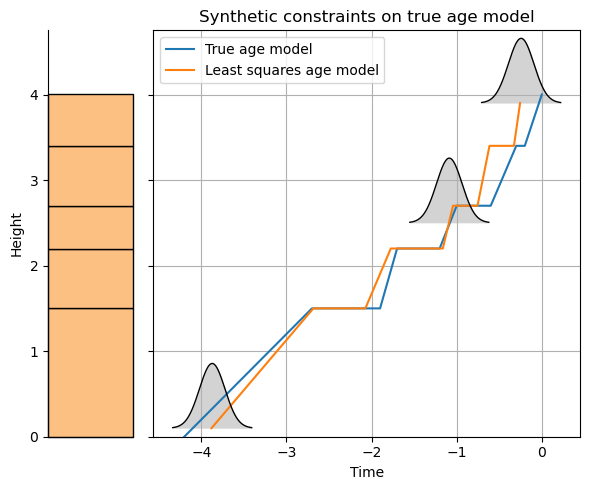

In [33]:
t_plot = np.linspace(np.min(times) - 3*sig_t, np.max(times) + 3*sig_t, 400)

# true age model
t_true, z = stratage.age_depth(units, times)
# parameters for plotting pdfs
tol = 3
scale = 0.75

fig, ax = plt.subplots(1, 2, width_ratios=[1, 5], figsize=(6,5), sharey=True)

ax[0].set_ylim([heights_ylim[0]-0.5, heights_ylim[1]+scale])
section.plot(style, ax=ax[0])
ax[0].set_xticks([])
ax[0].set_ylabel('Height')
ax[0].set_ylim([0, np.max(z)+scale])

ax[1].plot(t_true, z, label='True age model')
ax[1].plot(t_bdls, z_bdls, label='Least squares age model')

geochron.plot_constraints(ax=ax[1], scale=scale)

ax[1].grid()
ax[1].set_xlabel('Time')
ax[1].set_title('Synthetic constraints on true age model')
ax[1].legend()

plt.tight_layout()

plt.show()

The least-squares model generates a reasonable age model that passes through the maximum likelihood values of the geochronologic constraints. `StratAge` uses the least squares solution as the initial model for the Markov Chain sampling.

## `StratAge.AgeModel` Bayesian Sampling

To set up the Bayesian model, we must specify prior distributions over sedimentation rates and hiatus durations. These distributions must be defined as functions that have the signature that is expected for the `dist` argument in [`pymc.CustomDist(dist=dist)`](https://www.pymc.io/projects/docs/en/v5.14.0/api/distributions/generated/pymc.CustomDist.html), i.e. a signature of `dist(*dist_params, size)`. At this time, `StrageAge` cannot sample from hierarchical priors, meaning that prior distributions cannot require any `dist_params`. Therefore, the expected signature for prior distributions is just `prior(size)`.

Below, we use a log-normal prior over sedimentation rates, with a sigma of 1.2. We use a log-uniform prior over hiatus durations, ranging from 0.1 to 10. Notice that we are using `PyMC` distributions; any of the `PyMC` distributions should work analagously to what is shown below.

In [34]:
# all units have same sed rate prior
sed_rate_sigma = 1.2*np.ones(n_units)

def sed_rates_prior_fn(size):
    return pm.LogNormal.dist(sigma=sed_rate_sigma, size=size)

def hiatuses_prior_fn(size):
    return 10**pm.Uniform.dist(lower=-1, upper=1, size=size)

:::{note}
If you wanted to have different parameter values for the priors on different beds or contacts, then you would just need to specify parameter arrays accordingly. For example, if we wanted the first bed to have a narrower prior distribution of sedimentation rates, we could have defined `sed_rate_sigma` as follows:
```python
sed_rate_sigma = 1.2*np.ones(n_units)
sed_rate_sigma[0] = 0.5
```
:::

Now that we have both prior distributions and the `Geochron` object with the probabilistic geochronologic constraints, we can instantiate the `stratage.AgeModel` class.

In [35]:
agemodel = stratage.AgeModel(units, geochron, sed_rates_prior_fn, hiatuses_prior_fn)

This class creates an object with a `pymc.Model` as an attribute, which we can visualize.

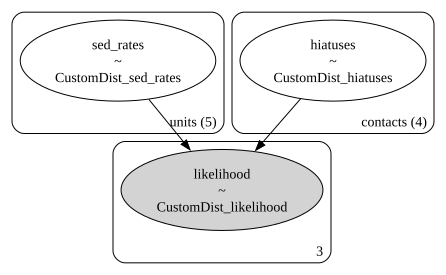

In [36]:
pm.model_to_graphviz(agemodel.model)

The model visualization shows that we have a random variable of sedimentation rates with a length of 5 and a random variable of hiatuses with a length of 4. The coordinates for these random variables are named "units" and "contacts," and the sizes make sense with our simple stratigraphy that has 5 units and 4 contacts. We also see that these random varialbes are sampled according to `CustomDist` distributions, which correspond to the priors we defined above.

These random variables feed into a likelihood, which has a length of 3. This size reflects the 3 time increment distributions from the 3 combinations of geochronologic constraints, which were plotted above. The likelihood is based on the time increment distributions from the 3 pairs of constraints, defining the `CustomDist_likelihood` in the diagram above. 

With the model defined above, we can use all the helpful and robust `PyMC` sampling tools. For example, we can sample from the prior distributions on sedimentation rates and hiatuses to see what sort of age models we would get.

In [37]:
times_prior = agemodel.sample_prior(draws=100)

Sampling: [hiatuses, likelihood, sed_rates]


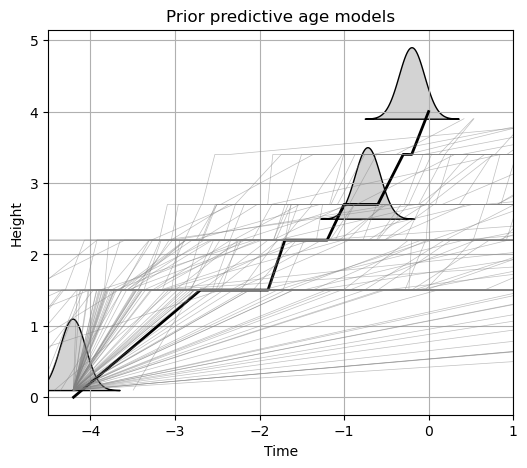

In [20]:
# true age model
t_true, z_true = stratage.age_depth(units, times)
# parameters for plotting pdfs
tol = 3
scale = 1

fig = plt.figure(figsize=(6,5))
ax = plt.axes()

# true age model and constraints
geochron.plot_constraints(ax=ax)
ax.plot(t_true, z_true, label='true age model', linewidth=2, color='k')

# prior predictive models
for ii in range(len(times_prior)):
    cur_t, cur_z = stratage.age_depth(units_trim, times_prior[ii])
    plt.plot(cur_t, cur_z, color='gray', linewidth=0.5, alpha=0.5)

ax.grid()
ax.set_xlabel('Time')
ax.set_ylabel('Height')
ax.set_title('Prior predictive age models')

ax.set_xlim([-4.5, 1])

plt.show()

The prior predictive models are not very good, as we can see in the figure above.

Let's now actually sample the Bayesian age model. We do so by invoking `stratage.AgeModel.sample()`, which accepts keyword arguments that are passed to `pymc.sample()`.

At this time, sampling is restricted to the conventional Metropolis sampler.

In [38]:
draws = 5000
tune = 2000
n_chains = 4

trace = agemodel.sample(draws=draws, tune=tune, chains=n_chains)

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [sed_rates]
>Metropolis: [hiatuses]


Output()

Sampling 4 chains for 2_000 tune and 5_000 draw iterations (8_000 + 20_000 draws total) took 83 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


We can use `arviz` to tabulate and plot helpful diagnostics for the chains that we sampled above.

In [39]:
az.summary(trace)

[autoreload of cutils_ext failed: Traceback (most recent call last):
  File "c:\Users\XPS\miniforge3\Lib\site-packages\IPython\extensions\autoreload.py", line 276, in check
    superreload(m, reload, self.old_objects)
  File "c:\Users\XPS\miniforge3\Lib\site-packages\IPython\extensions\autoreload.py", line 475, in superreload
    module = reload(module)
             ^^^^^^^^^^^^^^
  File "c:\Users\XPS\miniforge3\Lib\importlib\__init__.py", line 130, in reload
    raise ModuleNotFoundError(f"spec not found for the module {name!r}", name=name)
ModuleNotFoundError: spec not found for the module 'cutils_ext'
]


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sed_rates[0],3.108,2.847,0.616,7.667,0.230,0.163,53.0,29.0,1.07
sed_rates[1],1.698,1.880,0.351,5.053,0.160,0.113,59.0,74.0,1.03
sed_rates[2],4.302,7.592,0.300,11.833,0.853,0.617,152.0,111.0,1.02
sed_rates[3],6.889,12.806,1.021,15.780,1.455,1.033,273.0,157.0,1.02
sed_rates[4],5.140,5.354,0.744,14.158,0.303,0.225,511.0,457.0,1.01
hiatuses[0],0.516,0.406,0.100,1.328,0.043,0.031,105.0,150.0,1.03
hiatuses[1],0.567,0.452,0.100,1.445,0.068,0.048,42.0,177.0,1.08
hiatuses[2],0.207,0.101,0.100,0.402,0.003,0.002,1207.0,1022.0,1.00
hiatuses[3],0.204,0.101,0.100,0.392,0.003,0.002,1123.0,1212.0,1.00


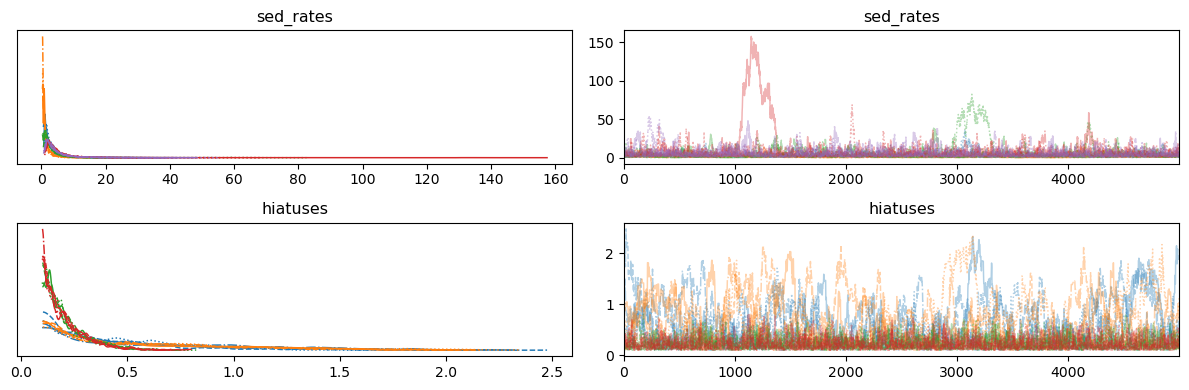

In [40]:
az.plot_trace(trace)
plt.tight_layout()
plt.show()

## Generating age models

`StratAge.AgeModel` implements a Bayesian model to generate samples of sedimentation rates and hiatuses, but, as mentioned above, these only yield floating age models by themselves. Sedimentation rates and hiatuses in the trace generated by the PyMC sampling can be aligned to the geochronology using the `StratAge.AgeModel.trace2ages()` function. 

This function returns posterior ages at requested stratigraphic heights. Note that this can take some time but is easily parallelized, so you can increase the `n_jobs` parameter to use more processes for large traces.

In [41]:
n_h = 500
h = np.linspace(np.min(units_trim), np.max(units_trim), n_h)

t_posterior = agemodel.trace2ages(trace, h=h, n_jobs=4, method='random')

Anchoring floating age models:   0%|          | 0/10000 [00:00<?, ?it/s]

In [42]:
ci_95 = np.quantile(t_posterior, [0.025, 0.975], axis=0)
ci_68 = np.quantile(t_posterior, [0.16, 0.84], axis=0)

We can evaluate quantiles on the posterior age models and finally plot the Bayesian age model.

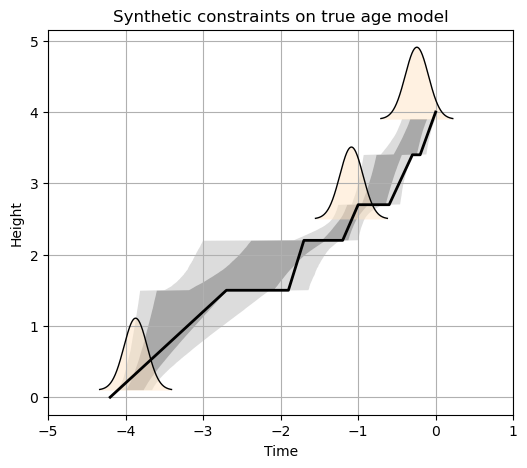

In [44]:
# true age model
t_true, z_true = stratage.age_depth(units, times)
# parameters for plotting pdfs
tol = 3
scale = 1

fig = plt.figure(figsize=(6,5))
ax = plt.axes()

# posterior predictive models
ax.fill_betweenx(h, ci_95[0, :], ci_95[1, :], facecolor='gainsboro')
ax.fill_betweenx(h, ci_68[0, :], ci_68[1, :], facecolor='darkgrey')

# true age model and constraints
geochron.plot_constraints(ax=ax, fillstyle={'facecolor':'bisque', 'alpha':0.5})
ax.plot(t_true, z_true, label='true age model', linewidth=2, color='k')

ax.grid()
ax.set_xlabel('Time')
ax.set_ylabel('Height')
ax.set_title('Synthetic constraints on true age model')

ax.set_xlim([-5, 1])

plt.show()

Here we can see how the structure of the posterior age model is distinctly different from existing age modeling approaches. The envelope shows "jumpiness" that reflects the possibility of hiatus at bedding contacts. We see that the true age model is solidly within the 95% credible interval, which is great. We can also see that the posterior distribution in absolute time for the middle geochronologic constraint is reduced compared to it's reported uncertainty. This reflects the incorporation of the prior information about sedimentation rates and hiatus durations, as well as stratigraphic superposition. 

## References

Haslett, J., and Parnell, A., 2008, A Simple Monotone Process with Application to Radiocarbon-Dated Depth Chronologies: Journal of the Royal Statistical Society Series C: Applied Statistics, v. 57, p. 399–418, doi:10.1111/j.1467-9876.2008.00623.x.
